# Melanoma & Nevus — EfficientNet-B3 (300×300) + chuẩn hóa màu Shades of Gray

Cải tiến từ `07_train_improved.ipynb`, nhắm vào 2 điểm yếu thấy được ở external validation (`08`) và Grad-CAM (`09`):

1. **Chuẩn hóa màu Shades of Gray** — ảnh từ thiết bị/nguồn khác nhau lệch màu nhiều (domain shift). Đưa màu ánh sáng của mọi ảnh về xám trung tính trước khi vào model.
2. **EfficientNet-B3 ở 300×300** (thay B0 ở 224×224) — các ca melanoma bị bỏ sót thường "trông giống nevus", cần nhìn được chi tiết hoa văn nhỏ hơn.

Loss, augmentation, TTA, threshold Youden giữ nguyên như 07. Thêm mixed precision (AMP) để train nhanh hơn trên GPU.

**v2** (bản hiện tại): lần chạy đầu (v1, learning rate 1e-4 như 07) đạt val AUC cao nhất ngay epoch 2 rồi overfit — B3 lớn hơn B0 nên học thuộc tập train quá nhanh. v2 hạ learning rate xuống **3e-5**, tăng patience lên **5** và số epoch tối đa lên **20**. Checkpoint v2 lưu tên `best_model_b3_cc_v2.pt` / `last_model_b3_cc_v2.pt`, không đụng checkpoint của v1 và của 07.

Kết quả v1 trên test set gốc: AUC 0.8880, accuracy 0.8190, sensitivity 0.7621 (07: 0.9011 / 0.8313 / 0.8180). Trên test set ngoài (PAD-UFES-20 + BALD) v1 lại hơn 07: AUC 0.927 so với 0.914, chủ yếu nhờ BALD.

Cần GPU (Colab/Kaggle) — B3 ở 300×300 trên CPU quá chậm.

##### 1. Setup — chạy lại image pipeline

In [1]:
import os

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

IN_KAGGLE = os.path.exists('/kaggle/input')

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    pipeline_path = '/content/drive/MyDrive/Melanoma/04_image_pipeline.ipynb'
elif IN_KAGGLE:
    pipeline_path = None
    for root, dirs, files in os.walk('/kaggle/input'):
        if '04_image_pipeline.ipynb' in files:
            pipeline_path = os.path.join(root, '04_image_pipeline.ipynb')
            break
    if pipeline_path is None:
        raise FileNotFoundError(
            'Không tìm thấy 04_image_pipeline.ipynb trong /kaggle/input - '
            'nhớ upload file này vào dataset'
        )
else:
    pipeline_path = '04_image_pipeline.ipynb'

print('pipeline_path:', pipeline_path)
%run {pipeline_path}

Mounted at /content/drive
pipeline_path: /content/drive/MyDrive/Melanoma/04_image_pipeline.ipynb
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Giải nén /content/drive/MyDrive/Melanoma/images.zip ra /content/images ...
Xong.
IN_COLAB: True
IMAGES_DIR: /content/images
PROCESSED_DIR: /content/drive/MyDrive/Melanoma/data/processed
Train: (12696, 25) | Val: (2752, 25) | Test: (2685, 25)
Số file không tồn tại (trong 20 mẫu đầu): 0
Số batch - train: 397 | val: 86 | test: 84
images shape : torch.Size([32, 3, 224, 224])
labels shape : torch.Size([32]) | vài label đầu: [1, 0, 1, 0, 0, 0, 0, 0]
metadata shape: torch.Size([32, 13])


In [2]:
import torch

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
use_amp = device.type == 'cuda'
print('Device:', device, '| AMP:', use_amp)

Device: cuda | AMP: True


##### 2. Chuẩn hóa màu Shades of Gray + transform 300×300

Shades of Gray (Finlayson & Trezzi, 2004): ước lượng màu ánh sáng của ảnh bằng trung bình bậc p (p = 6) của từng kênh màu, rồi chia lại từng kênh để ánh sáng thành xám trung tính. Ảnh được resize trước rồi mới chuẩn hóa màu (ước lượng ánh sáng trên ảnh nhỏ gần như giống hệt ảnh gốc, nhưng nhanh hơn nhiều). Áp cho cả train và val/test; augmentation (flip, xoay, color jitter) giữ nguyên như 07 và chạy sau bước chuẩn hóa màu.

Dataset/DataLoader dựng lại từ `MelanomaDataset`, `df_train/df_val/df_test`, `BATCH_SIZE`, `NUM_WORKERS` của `04_image_pipeline.ipynb`.

In [3]:
import numpy as np
from PIL import Image
from torch.utils.data import DataLoader
from torchvision import transforms


class ShadesOfGray:
    def __init__(self, power=6):
        self.power = power

    def __call__(self, image):
        img = np.asarray(image, dtype=np.float32)
        illum = np.power(np.mean(np.power(img, self.power), axis=(0, 1)), 1 / self.power)
        illum = illum / (np.sqrt(np.sum(illum ** 2)) + 1e-8)
        img = img / (illum * np.sqrt(3) + 1e-8)
        return Image.fromarray(np.clip(img, 0, 255).astype(np.uint8))


IMAGE_SIZE = 300

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    ShadesOfGray(),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    ShadesOfGray(),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

train_loader = DataLoader(MelanomaDataset(df_train, transform=train_transform), batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
val_loader = DataLoader(MelanomaDataset(df_val, transform=eval_transform), batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(MelanomaDataset(df_test, transform=eval_transform), batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

images, labels, metadata = next(iter(train_loader))
print('images shape:', images.shape)  # kỳ vọng (batch, 3, 300, 300)

images shape: torch.Size([32, 3, 300, 300])


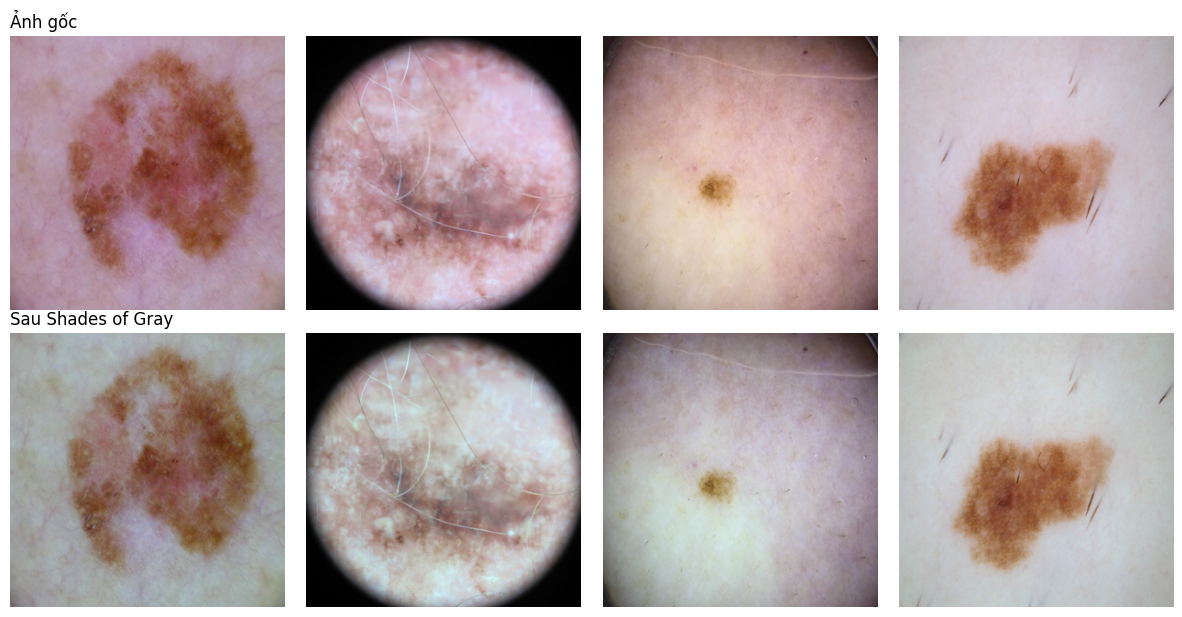

In [4]:
import matplotlib.pyplot as plt

sample = df_train.sample(4, random_state=0)
fig, axes = plt.subplots(2, 4, figsize=(12, 6.2))
for col, path in enumerate(sample['image_path']):
    img = Image.open(path).convert('RGB').resize((IMAGE_SIZE, IMAGE_SIZE))
    axes[0, col].imshow(img)
    axes[1, col].imshow(ShadesOfGray()(img))
    for ax in axes[:, col]:
        ax.axis('off')
axes[0, 0].set_title('Ảnh gốc', loc='left')
axes[1, 0].set_title('Sau Shades of Gray', loc='left')
plt.tight_layout()
plt.show()

##### 3. Model — EfficientNet-B3 + metadata MLP

Giống `MultimodalModel` của 07, chỉ đổi backbone sang `efficientnet_b3` (feature **1536 chiều** thay vì 1280).

In [5]:
import torch.nn as nn
from torchvision.models import EfficientNet_B3_Weights, efficientnet_b3


class MultimodalModel(nn.Module):
    def __init__(self, n_metadata_features, image_feature_dim=1536, metadata_hidden_dim=32):
        super().__init__()

        backbone = efficientnet_b3(weights=EfficientNet_B3_Weights.IMAGENET1K_V1)
        backbone.classifier = nn.Identity()
        self.image_branch = backbone

        self.metadata_branch = nn.Sequential(
            nn.Linear(n_metadata_features, metadata_hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.3),
        )

        self.classifier = nn.Linear(image_feature_dim + metadata_hidden_dim, 1)

    def forward(self, image, metadata):
        image_features = self.image_branch(image)
        metadata_features = self.metadata_branch(metadata)
        combined = torch.cat([image_features, metadata_features], dim=1)
        return self.classifier(combined)


model = MultimodalModel(n_metadata_features=len(METADATA_COLS)).to(device)
print(model.classifier)

Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 182MB/s]


Linear(in_features=1568, out_features=1, bias=True)


##### 4. Loss — Focal Loss (giống 07), optimizer Adam với learning rate 3e-5 (07 dùng 1e-4)

In [6]:
import torch.optim as optim
from torchvision.ops import sigmoid_focal_loss

n_nevus = (df_train['diagnosis'] == 'nevus').sum()
n_melanoma = (df_train['diagnosis'] == 'melanoma').sum()

FOCAL_ALPHA = n_nevus / (n_nevus + n_melanoma)
FOCAL_GAMMA = 2.0
print(f'FOCAL_ALPHA: {FOCAL_ALPHA:.4f} | FOCAL_GAMMA: {FOCAL_GAMMA}')


def criterion(outputs, targets):
    return sigmoid_focal_loss(outputs, targets, alpha=FOCAL_ALPHA, gamma=FOCAL_GAMMA, reduction='mean')


optimizer = optim.Adam(model.parameters(), lr=3e-5)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=1)
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

FOCAL_ALPHA: 0.6011 | FOCAL_GAMMA: 2.0


##### 5. Hàm train 1 epoch / đánh giá (có AMP, không TTA — dùng theo dõi val mỗi epoch)

In [7]:
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score, roc_auc_score


def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0

    for images, labels, metadata in loader:
        images = images.to(device)
        metadata = metadata.to(device)
        labels = labels.float().unsqueeze(1).to(device)

        optimizer.zero_grad()
        with torch.autocast(device_type=device.type, enabled=use_amp):
            outputs = model(images, metadata)
        loss = criterion(outputs.float(), labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * images.size(0)

    return total_loss / len(loader.dataset)


@torch.no_grad()
def evaluate(model, loader, criterion, device, threshold=0.5):
    model.eval()
    total_loss = 0.0
    all_labels, all_probs = [], []

    for images, labels, metadata in loader:
        images = images.to(device)
        metadata = metadata.to(device)
        labels_t = labels.float().unsqueeze(1).to(device)

        with torch.autocast(device_type=device.type, enabled=use_amp):
            outputs = model(images, metadata)
        outputs = outputs.float()
        total_loss += criterion(outputs, labels_t).item() * images.size(0)

        all_probs.extend(torch.sigmoid(outputs).cpu().numpy().flatten())
        all_labels.extend(labels.numpy())

    preds = [1 if p >= threshold else 0 for p in all_probs]

    metrics = {
        'loss': total_loss / len(loader.dataset),
        'accuracy': accuracy_score(all_labels, preds),
        'sensitivity': recall_score(all_labels, preds),
        'auc': roc_auc_score(all_labels, all_probs),
    }
    return metrics, all_labels, preds, all_probs

##### 6. Training loop với early stopping (resume được sau khi bị ngắt)

Lưu 2 checkpoint riêng:

- `best_model_b3_cc_v2.pt` — trọng số có val AUC tốt nhất, dùng để đánh giá cuối.
- `last_model_b3_cc_v2.pt` — toàn bộ trạng thái **sau mỗi epoch** (model, optimizer, AMP scaler, scheduler, epoch, best AUC, bộ đếm early stopping), dùng để resume.

Bị ngắt thì chỉ cần kết nối lại và **Run all**: notebook đọc `last_model_b3_cc_v2.pt` và train tiếp đúng epoch kế tiếp với learning rate/early stopping như chưa từng bị ngắt — chỉ mất phần epoch đang chạy dở. Checkpoint được ghi ra file tạm rồi mới thay thế, nên bị ngắt đúng lúc đang ghi cũng không làm hỏng checkpoint cũ. Nếu lần trước đã train xong (hết epoch hoặc đã early stop), chạy lại sẽ bỏ qua phần train và chỉ đánh giá.

- **Colab**: checkpoint nằm trên Drive nên còn nguyên sau khi bị ngắt; phải để tab mở trong lúc train.
- **Kaggle**: nên dùng **Save Version → Save & Run All** — chạy ngầm trên server (tối đa 12 tiếng), tắt trình duyệt vẫn chạy. Chạy tương tác thì `/kaggle/working` mất theo session, resume không có tác dụng.

In [8]:
EPOCHS = 20
PATIENCE = 5

if IN_COLAB:
    CHECKPOINT_DIR = DRIVE_ROOT
elif IN_KAGGLE:
    CHECKPOINT_DIR = '/kaggle/working'
else:
    CHECKPOINT_DIR = '.'

BEST_PATH = os.path.join(CHECKPOINT_DIR, 'best_model_b3_cc_v2.pt')
LAST_PATH = os.path.join(CHECKPOINT_DIR, 'last_model_b3_cc_v2.pt')
print('BEST_PATH:', BEST_PATH)
print('LAST_PATH:', LAST_PATH)


def atomic_save(obj, path):
    # ghi ra file tạm rồi mới thay thế: bị ngắt giữa lúc ghi thì checkpoint cũ vẫn nguyên vẹn
    tmp_path = path + '.tmp'
    torch.save(obj, tmp_path)
    os.replace(tmp_path, path)


start_epoch = 1
best_val_auc = 0.0
epochs_no_improve = 0

if os.path.exists(LAST_PATH):
    state = torch.load(LAST_PATH, map_location=device, weights_only=False)
    model.load_state_dict(state['model_state_dict'])
    optimizer.load_state_dict(state['optimizer_state_dict'])
    scaler.load_state_dict(state['scaler_state_dict'])
    scheduler.load_state_dict(state['scheduler_state_dict'])
    start_epoch = state['epoch'] + 1
    best_val_auc = state['best_val_auc']
    epochs_no_improve = state['epochs_no_improve']
    print(f"Resume từ epoch {start_epoch} | best_val_auc={best_val_auc:.4f} | "
          f"epochs_no_improve={epochs_no_improve} | lr={optimizer.param_groups[0]['lr']:.2e}")
else:
    print('Không có checkpoint cũ - train từ đầu')

if epochs_no_improve >= PATIENCE or start_epoch > EPOCHS:
    print('Lần chạy trước đã train xong - bỏ qua training, chỉ đánh giá')

for epoch in range(start_epoch, EPOCHS + 1):
    if epochs_no_improve >= PATIENCE:
        break

    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_metrics, _, _, _ = evaluate(model, val_loader, criterion, device)

    scheduler.step(val_metrics['auc'])

    print(f"Epoch {epoch:02d} | train_loss={train_loss:.4f} "
          f"| val_loss={val_metrics['loss']:.4f} val_acc={val_metrics['accuracy']:.4f} "
          f"val_sensitivity={val_metrics['sensitivity']:.4f} val_auc={val_metrics['auc']:.4f} "
          f"lr={optimizer.param_groups[0]['lr']:.2e}")

    if val_metrics['auc'] > best_val_auc:
        best_val_auc = float(val_metrics['auc'])
        epochs_no_improve = 0
        atomic_save({'model_state_dict': model.state_dict(), 'epoch': epoch, 'best_val_auc': best_val_auc}, BEST_PATH)
        print(f'  -> Lưu best checkpoint (val_auc={best_val_auc:.4f})')
    else:
        epochs_no_improve += 1

    atomic_save({
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scaler_state_dict': scaler.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'epoch': epoch,
        'best_val_auc': best_val_auc,
        'epochs_no_improve': epochs_no_improve,
    }, LAST_PATH)

    if epochs_no_improve >= PATIENCE:
        print(f'Early stopping tại epoch {epoch} (không cải thiện sau {PATIENCE} epoch)')

print('\nBest val AUC:', best_val_auc)

BEST_PATH: /content/drive/MyDrive/Melanoma/best_model_b3_cc_v2.pt
LAST_PATH: /content/drive/MyDrive/Melanoma/last_model_b3_cc_v2.pt
Không có checkpoint cũ - train từ đầu
Epoch 01 | train_loss=0.0678 | val_loss=0.0612 val_acc=0.7674 val_sensitivity=0.7431 val_auc=0.8355 lr=3.00e-05
  -> Lưu best checkpoint (val_auc=0.8355)
Epoch 02 | train_loss=0.0575 | val_loss=0.0568 val_acc=0.8034 val_sensitivity=0.7255 val_auc=0.8636 lr=3.00e-05
  -> Lưu best checkpoint (val_auc=0.8636)
Epoch 03 | train_loss=0.0524 | val_loss=0.0540 val_acc=0.8129 val_sensitivity=0.7144 val_auc=0.8806 lr=3.00e-05
  -> Lưu best checkpoint (val_auc=0.8806)
Epoch 04 | train_loss=0.0486 | val_loss=0.0532 val_acc=0.8136 val_sensitivity=0.7662 val_auc=0.8858 lr=3.00e-05
  -> Lưu best checkpoint (val_auc=0.8858)
Epoch 05 | train_loss=0.0448 | val_loss=0.0524 val_acc=0.8223 val_sensitivity=0.7763 val_auc=0.8895 lr=3.00e-05
  -> Lưu best checkpoint (val_auc=0.8895)
Epoch 06 | train_loss=0.0417 | val_loss=0.0539 val_acc=0.820

##### 7. Hàm đánh giá có TTA (giống 07)

In [9]:
@torch.no_grad()
def evaluate_tta(model, loader, criterion, device, threshold=0.5):
    model.eval()
    total_loss = 0.0
    all_labels, all_probs = [], []

    for images, labels, metadata in loader:
        images = images.to(device)
        metadata = metadata.to(device)
        labels_t = labels.float().unsqueeze(1).to(device)

        views = [
            images,
            torch.flip(images, dims=[3]),
            torch.flip(images, dims=[2]),
            torch.flip(images, dims=[2, 3]),
        ]
        with torch.autocast(device_type=device.type, enabled=use_amp):
            outputs_per_view = [model(v, metadata).float() for v in views]

        total_loss += criterion(outputs_per_view[0], labels_t).item() * images.size(0)

        probs_avg = torch.stack([torch.sigmoid(o) for o in outputs_per_view]).mean(dim=0)
        all_probs.extend(probs_avg.cpu().numpy().flatten())
        all_labels.extend(labels.numpy())

    preds = [1 if p >= threshold else 0 for p in all_probs]

    metrics = {
        'loss': total_loss / len(loader.dataset),
        'accuracy': accuracy_score(all_labels, preds),
        'sensitivity': recall_score(all_labels, preds),
        'auc': roc_auc_score(all_labels, all_probs),
    }
    return metrics, all_labels, preds, all_probs

##### 8. Đánh giá cuối cùng trên test set với TTA (chỉ chạy 1 lần, threshold=0.5)

In [10]:
best = torch.load(BEST_PATH, map_location=device, weights_only=False)
model.load_state_dict(best['model_state_dict'])
print(f"Đánh giá best checkpoint: epoch {best['epoch']}, val_auc={best['best_val_auc']:.4f}")

test_metrics, test_labels, test_preds, test_probs = evaluate_tta(model, test_loader, criterion, device)

print('=== Test set metrics (TTA, threshold=0.5) ===')
for k, v in test_metrics.items():
    print(f'{k}: {v:.4f}')

print('\nConfusion matrix (hàng=thật, cột=dự đoán, 0=nevus, 1=melanoma):')
print(confusion_matrix(test_labels, test_preds))

Đánh giá best checkpoint: epoch 7, val_auc=0.8916
=== Test set metrics (TTA, threshold=0.5) ===
loss: 0.0573
accuracy: 0.8223
sensitivity: 0.7488
auc: 0.8919

Confusion matrix (hàng=thật, cột=dự đoán, 0=nevus, 1=melanoma):
[[1418  212]
 [ 265  790]]


##### 9. So sánh với 07 (B0, 224×224, không chuẩn hóa màu) và v1 (learning rate 1e-4)

In [11]:
import pandas as pd

pd.DataFrame(
    {
        '07 — B0, 224': {'AUC': 0.9011, 'Accuracy': 0.8313, 'Sensitivity': 0.8180},
        '10 v1 — lr 1e-4': {'AUC': 0.8880, 'Accuracy': 0.8190, 'Sensitivity': 0.7621},
        '10 v2 — lr 3e-5': {
            'AUC': test_metrics['auc'],
            'Accuracy': test_metrics['accuracy'],
            'Sensitivity': test_metrics['sensitivity'],
        },
    }
).round(4)

,"07 — B0, 224",10 v1 — lr 1e-4,10 v2 — lr 3e-5
AUC,0.9011,0.8880,0.8919
Accuracy,0.8313,0.8190,0.8223
Sensitivity,0.8180,0.7621,0.7488


##### 10. Tune lại threshold trên val set (Youden's J, dùng TTA cho nhất quán)

In [ ]:
val_metrics, val_labels, _, val_probs = evaluate_tta(model, val_loader, criterion, device)

thresholds = np.arange(0.01, 1.0, 0.01)
best_threshold = 0.5
best_j = -1.0

for t in thresholds:
    preds = [1 if p >= t else 0 for p in val_probs]
    tn, fp, fn, tp = confusion_matrix(val_labels, preds).ravel()
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    j = sensitivity + specificity - 1

    if j > best_j:
        best_j = j
        best_threshold = t

print('Threshold mặc định: 0.50')
print(f"Threshold tối ưu (Youden's J trên val, TTA): {best_threshold:.2f} (J={best_j:.4f})")